<a href="https://colab.research.google.com/github/Rafif-AA/MMA3001-Final-Project/blob/main/MMA3001_Final_Project_Trial_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install ultralytics

In [ ]:
from ultralytics import YOLO

# Load YOLO26n model
model = YOLO("yolo26n.pt")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [ ]:
# Train the model on your custom dataset from Google Drive
results = model.train(data="/content/drive/MyDrive/DATASET 3 - Pork Rasher/data.yaml", epochs=100, imgsz=640)

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/DATASET 3 - Pork Rasher/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-4, nbs=64, nms=None, opset

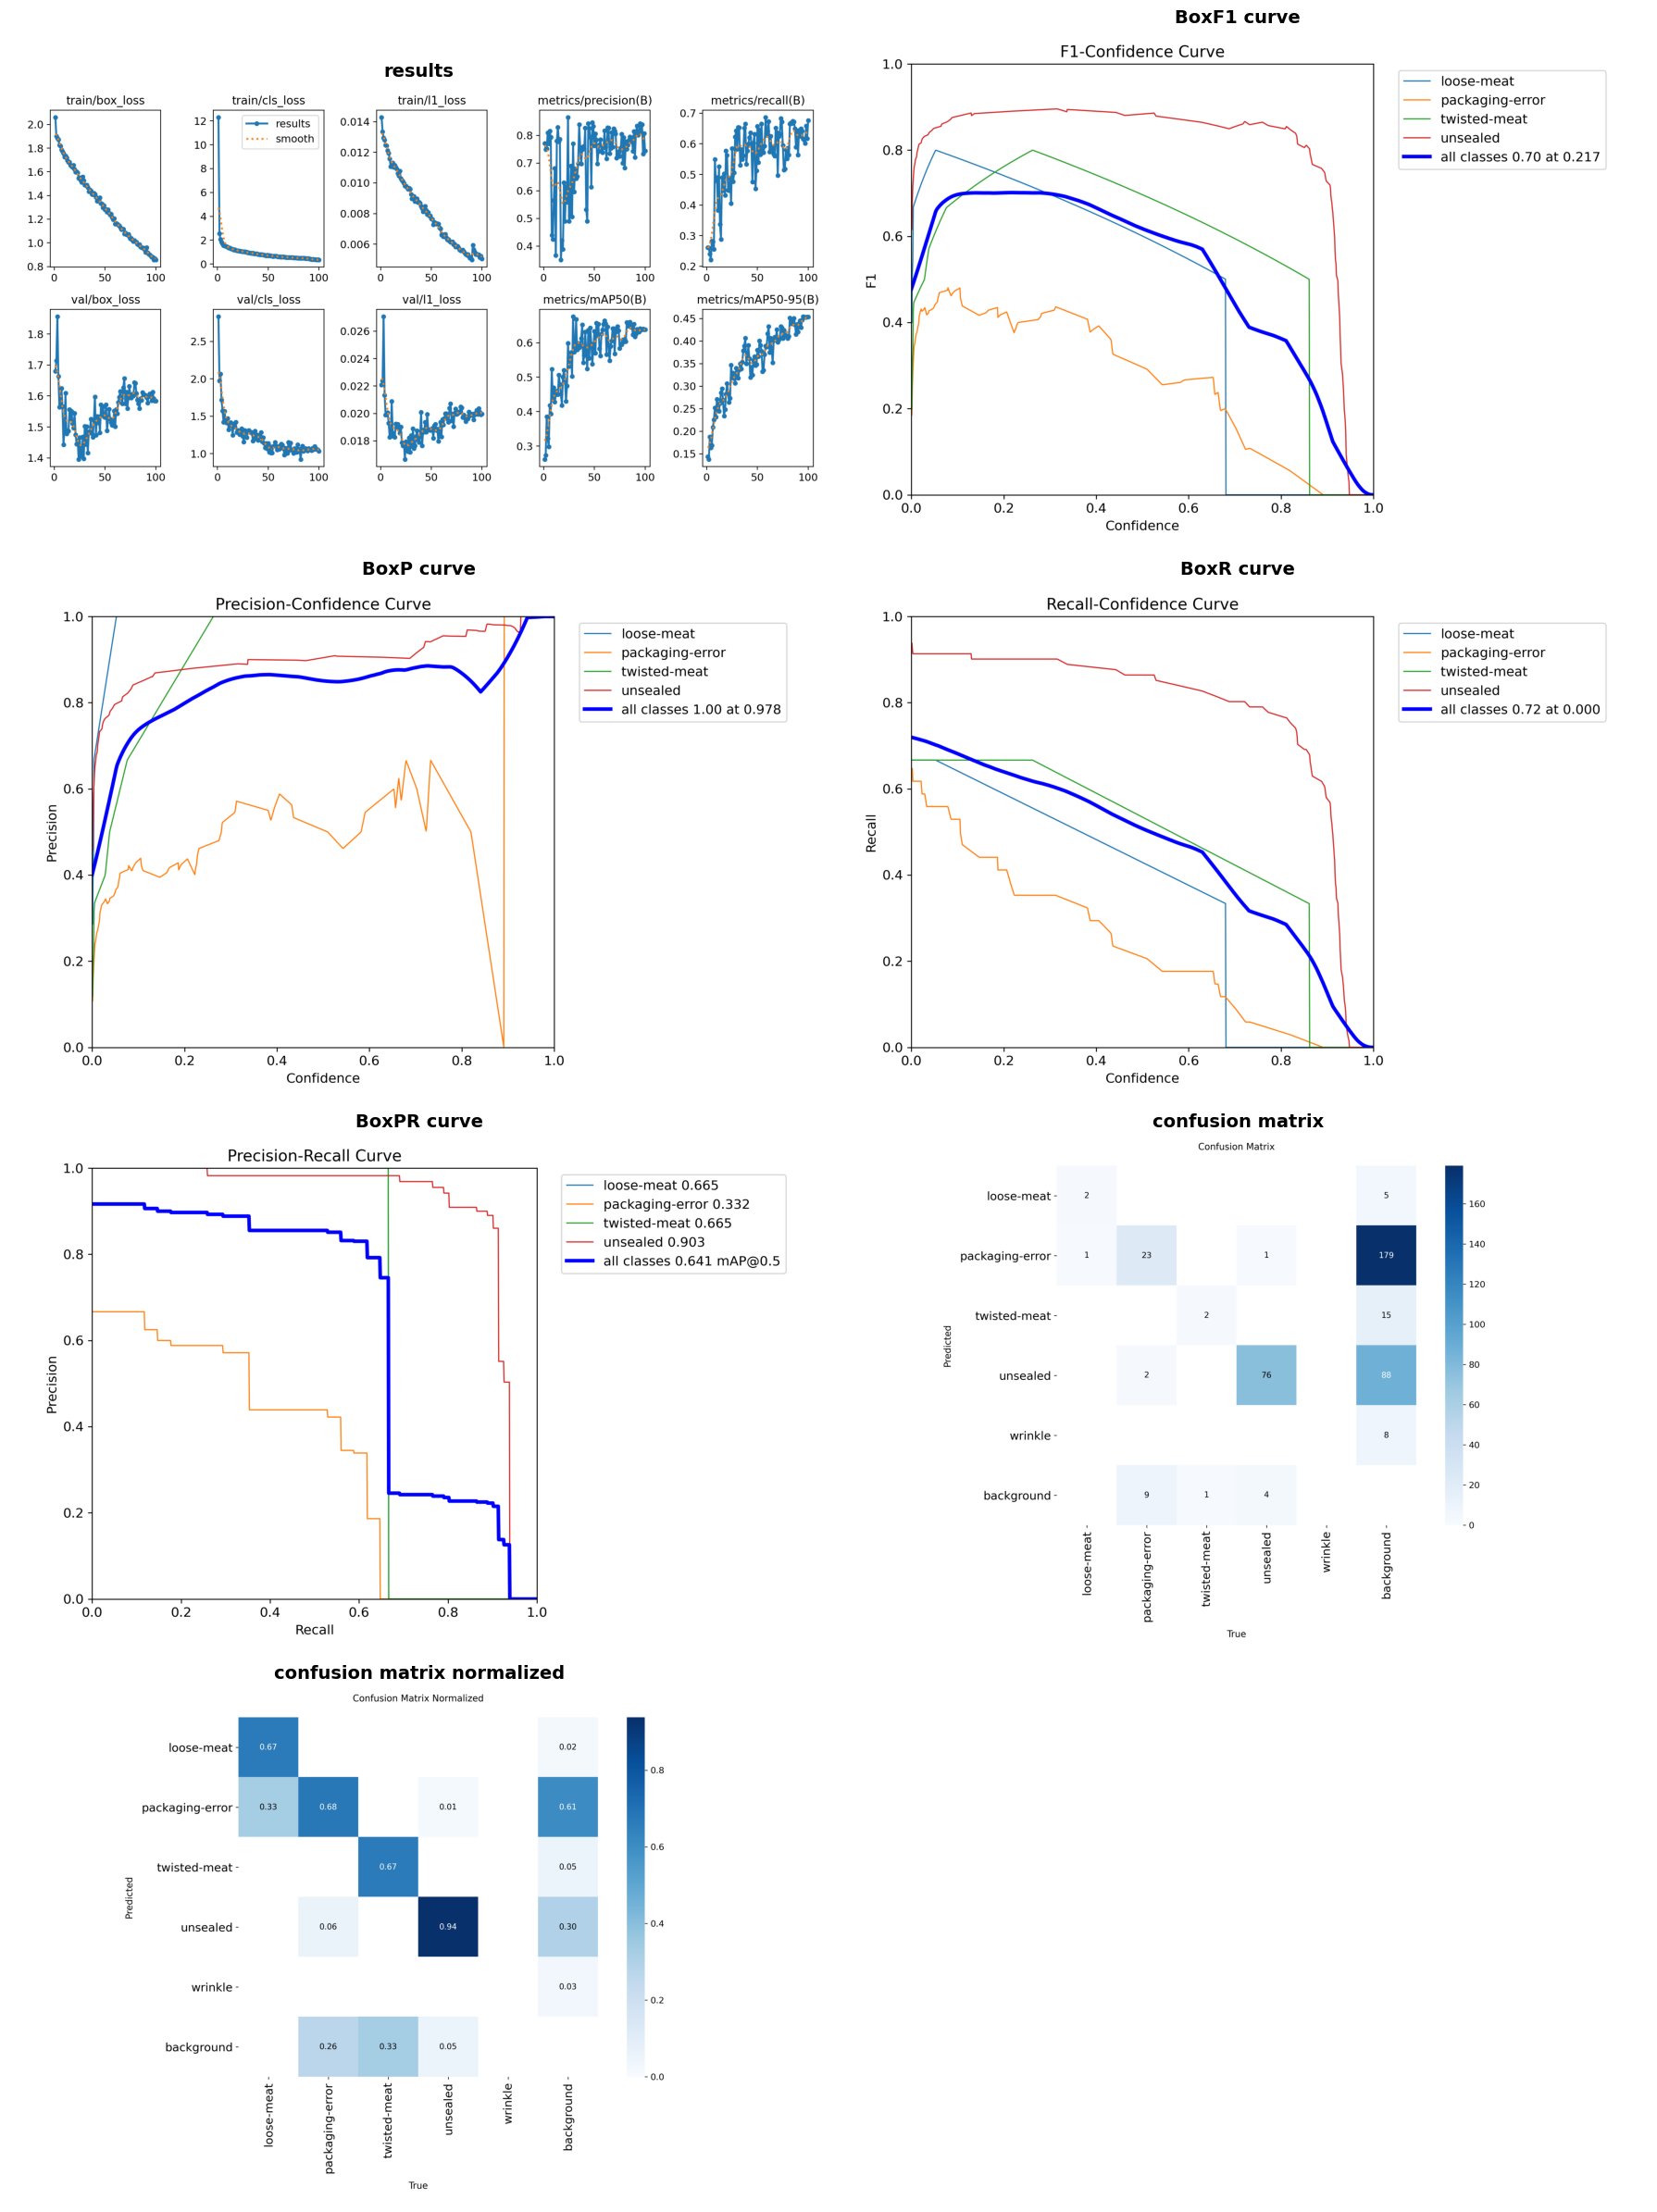

In [ ]:
import os
import matplotlib.pyplot as plt
from PIL import Image

# Path to your YOLO training results
results_dir = "/content/runs/detect/train-4"

# Evaluation plots to display
plot_files = [
    "results.png",
    "BoxF1_curve.png",
    "BoxP_curve.png",
    "BoxR_curve.png",
    "BoxPR_curve.png",
    "confusion_matrix.png",
    "confusion_matrix_normalized.png"
]

# Create a figure with 2 columns
fig, axes = plt.subplots(4, 2, figsize=(18, 24))
axes = axes.flatten()

for i, filename in enumerate(plot_files):
    filepath = os.path.join(results_dir, filename)

    if os.path.exists(filepath):
        img = Image.open(filepath)
        axes[i].imshow(img)
        axes[i].set_title(
            filename.replace("_", " ").replace(".png", ""),
            fontsize=14,
            fontweight="bold"
        )
    else:
        axes[i].text(
            0.5, 0.5,
            f"{filename}\nNot found",
            ha="center",
            va="center"
        )

    axes[i].axis("off")

# Hide unused subplot
for j in range(len(plot_files), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import torch
from ultralytics import YOLO

model = YOLO("/content/runs/detect/train-4/weights/best.pt")

network = model.model
network.eval()

device = next(network.parameters()).device

# Use a dummy image of size 640x640
dummy_input = torch.zeros(
    1, 3, 640, 640,
    device=device
)

layer_info = []
hooks = []

def make_hook(name):
    def hook(module, inputs, output):
        if isinstance(output, torch.Tensor):
            shape = tuple(output.shape)

            # Number of activations per image
            activations = output[0].numel()

            layer_info.append({
                "Layer": name,
                "Type": type(module).__name__,
                "Output Shape": shape,
                "Activations": activations
            })
    return hook

# Register hooks on leaf modules
for name, module in network.named_modules():
    if name and len(list(module.children())) == 0:
        hooks.append(
            module.register_forward_hook(make_hook(name))
        )

# Perform forward pass
with torch.no_grad():
    _ = network(dummy_input)

# Remove hooks
for hook in hooks:
    hook.remove()

# Display results
import pandas as pd

df = pd.DataFrame(layer_info)

display(df)

print("Total recorded activations:",
      f"{df['Activations'].sum():,}")

,Layer,Type,Output Shape,Activations
0,model.0.conv,Conv2d,"(1, 16, 320, 320)",1638400
1,model.0.bn,BatchNorm2d,"(1, 16, 320, 320)",1638400
2,model.0.act,SiLU,"(1, 16, 320, 320)",1638400
3,model.1.conv,Conv2d,"(1, 32, 160, 160)",819200
4,model.1.bn,BatchNorm2d,"(1, 32, 160, 160)",819200
...,...,...,...,...
359,model.23.one2one_cv3.2.1.1.conv,Conv2d,"(1, 80, 20, 20)",32000
360,model.23.one2one_cv3.2.1.1.bn,BatchNorm2d,"(1, 80, 20, 20)",32000
361,model.23.one2one_cv3.0.0.0.act,SiLU,"(1, 80, 20, 20)",32000
362,model.23.one2one_cv3.2.2,Conv2d,"(1, 5, 20, 20)",2000


Total recorded activations: 63,685,600
